In [12]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

import json 

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

from sklearn.metrics import confusion_matrix
import seaborn as sns

In [82]:
def matching_raman(ref_library, spectra_data_raman, limits, lib_name, data_name):
    
    #lim1, lim2 = limits
    lim1 = limits

    wn_gl = np.array(spectra_data_raman.columns[:-3])

    idx_gl = list(np.logical_and(wn_gl > lim1[0], wn_gl < lim1[1])) + [False]*3


    wn_fl = np.array(ref_library.columns[:-4])

    idx_fl = list(np.logical_and(wn_fl > lim1[0], wn_fl < lim1[1])) + [False]*4
    
    #idx_fl[np.where(idx_fl)[0][-1]] = False

    x_train_raman = ref_library.iloc[:,idx_fl].to_numpy()
    x_train_raman = norm_spect_pivot(x_train_raman, norm_type='SNV')
    y_train_raman = ref_library.iloc[:,-2]


    x_test_raman = spectra_data_raman.loc[:,idx_gl].to_numpy()
    x_test_raman = norm_spect_pivot(x_test_raman, norm_type='SNV')
    
    pred_ = corr_matching(x_train_raman, y_train_raman, 
                          x_test_raman, r_min=0)
    pred_polymers = pred_[0]
    pred_hqi = pred_[1]
    pred_df = pd.DataFrame(pred_polymers)
    pred_df = pred_df.reset_index(drop=True) 
    polymer_name = 'polymer_'+lib_name
    hqi_name = 'hqi_'+lib_name
    pred_df.columns = [polymer_name]
    pred_df[hqi_name] = pred_hqi
    
    #pred_df['background_'+data_name] = spectra_data_ir['background']
    #matches_mean = pred_df.reset_index().query('@hqi_name>.7').query('background!="background"').groupby(polymer_name).count()[hqi_name]

    #spectra_data_ir['polymer_flopp'] = pred_df['polymer_flopp']
    #spectra_data_ir['hqi_flopp'] = pred_df['hqi_flopp']

    return pred_df, pred_

In [83]:
with open('gloves_contamination/gloves_data_raman_saturation.json', 'r') as f:
    sat_wn_gloves = json.load(f)
sat_wn_gloves = {key:np.int64(sat_wn_gloves[key].split(',')) for key in sat_wn_gloves.keys()}
with open('gloves_contamination/stearates_data_raman_saturation.json', 'r') as f:
    sat_wn_stear = json.load(f)
    
sat_ids_gloves = list(sat_wn_gloves.keys())
sat_ids_stear = list(sat_wn_stear.keys())

In [84]:
stearates_df = pd.read_csv('gloves_contamination/stearates_data_raman_final_specy.csv')
del stearates_df['Unnamed: 0']
stearates_df.columns = list(np.float64(stearates_df.columns[:-4])) + list(stearates_df.columns[-4:])
stearates_df = stearates_df.query('id not in @sat_ids_stear').reset_index(drop=True)

stearates_no_bc_df = pd.read_csv('gloves_contamination/stearates_data_raman_final_no_bc.csv')
del stearates_no_bc_df['Unnamed: 0']
stearates_no_bc_df.columns = list(np.float64(stearates_no_bc_df.columns[:-4])) + list(stearates_no_bc_df.columns[-4:])
stearates_no_bc_df = stearates_no_bc_df.query('id not in @sat_ids_stear').reset_index(drop=True)

gloves_data_raman = pd.read_csv('gloves_contamination/gloves_data_raman_final_specy.csv')
del gloves_data_raman['Unnamed: 0']
gloves_data_raman.columns = list(np.float64(gloves_data_raman.columns[:-3])) + list(gloves_data_raman.columns[-3:])
gloves_data_raman# = gloves_data_raman.query('background == "no_background"')
gloves_data_raman = gloves_data_raman.query('id not in @sat_ids_gloves').reset_index(drop=True)

gloves_data_raman_no_bc = pd.read_csv('gloves_contamination/gloves_data_raman_final_no_bc.csv')
del gloves_data_raman_no_bc['Unnamed: 0']
gloves_data_raman_no_bc.columns = list(np.float64(gloves_data_raman_no_bc.columns[:-3])) + list(gloves_data_raman_no_bc.columns[-3:])
gloves_data_raman_no_bc# = gloves_data_raman.query('background == "no_background"')
gloves_data_raman_no_bc = gloves_data_raman_no_bc.query('id not in @sat_ids_gloves').reset_index(drop=True)


In [85]:
stearates_df.shape, stearates_no_bc_df.shape, gloves_data_raman.shape, gloves_data_raman_no_bc.shape

((159, 1577), (159, 1577), (1239, 1576), (1239, 1576))

In [86]:
gloves_data_raman

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3487.0,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,id
0,0.068679,0.074065,0.071034,0.065058,0.047093,0.033149,0.026839,0.011299,-0.010163,0.012040,...,-0.187298,-0.187298,-0.187298,-0.187298,-0.187298,-0.187298,-0.187298,15624.450195,1545.449951,MF_L_01_0514_1
1,0.639523,0.605787,0.593576,0.588226,0.605935,0.638924,0.700918,0.677862,0.600250,0.548362,...,-0.606618,-0.606618,-0.606618,-0.606618,-0.606618,-0.606618,-0.606618,15623.299805,1550.750000,MF_L_01_0514_2
2,2.712312,2.882443,2.986626,3.064666,3.013808,2.937730,2.813776,2.706437,2.609756,2.684483,...,-0.813815,-0.813815,-0.813815,-0.813815,-0.813815,-0.813815,-0.813815,15617.500000,1564.949951,MF_L_01_0514_3
3,0.132527,0.125327,0.127415,0.130922,0.126859,0.119735,0.106798,0.104577,0.109229,0.105809,...,-0.226923,-0.226923,-0.226923,-0.226923,-0.226923,-0.226923,-0.226923,15620.650391,1565.050049,MF_L_01_0514_4
4,1.606523,1.639777,1.717443,1.794196,1.747182,1.683180,1.586928,1.492610,1.399531,1.431163,...,-0.712308,-0.712308,-0.712308,-0.712308,-0.712308,-0.712308,-0.712308,15616.150391,1570.400024,MF_L_01_0514_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1234,0.114177,0.105439,0.110182,0.117332,0.117448,0.113142,0.100444,0.103548,0.116788,0.104578,...,-0.391525,-0.388703,-0.364579,-0.358846,-0.382970,-0.391525,-0.391525,-4543.500000,-1759.750000,KC_N_02_0328_28
1235,0.437370,0.444869,0.446204,0.443742,0.413838,0.398329,0.410147,0.409680,0.401332,0.377332,...,-0.500589,-0.500589,-0.500589,-0.500589,-0.500589,-0.500589,-0.500589,-4501.899902,-1758.099976,KC_N_02_0328_29
1236,0.848493,0.941898,0.958407,0.953525,0.901739,0.860630,0.839792,0.838897,0.850794,0.812097,...,-0.549846,-0.549846,-0.549846,-0.549846,-0.549846,-0.549846,-0.549846,-4510.850098,-1747.099976,KC_N_02_0328_30
1237,-0.041655,-0.056600,-0.058043,-0.056168,-0.051042,-0.052543,-0.066624,-0.070305,-0.067314,-0.065294,...,-0.315033,-0.315033,-0.315033,-0.315033,-0.315033,-0.315033,-0.315033,-4511.100098,-1743.050049,KC_N_02_0328_31


In [87]:
pred_stearates_df = matching_raman(stearates_df, gloves_data_raman, limits=(355,3500), lib_name='ref', data_name='final')
pred_stearates_no_bc_df = matching_raman(stearates_no_bc_df, gloves_data_raman_no_bc, limits=(355,3500), lib_name='ref', data_name='final')


Calcium Stearate


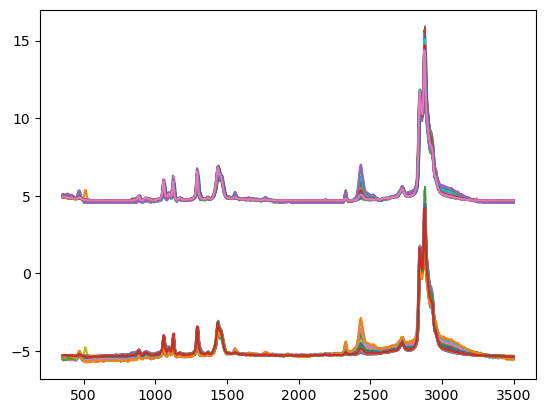

Magnesium Stearate v2


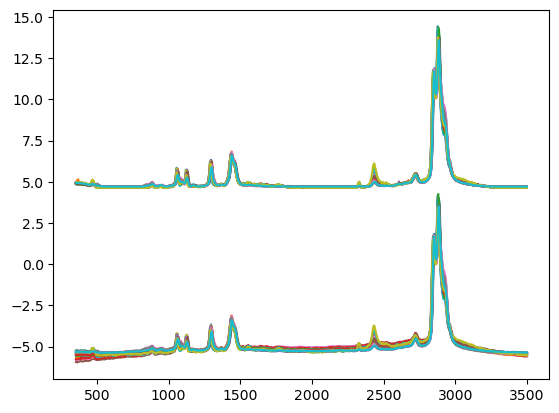

Sodium Stearate


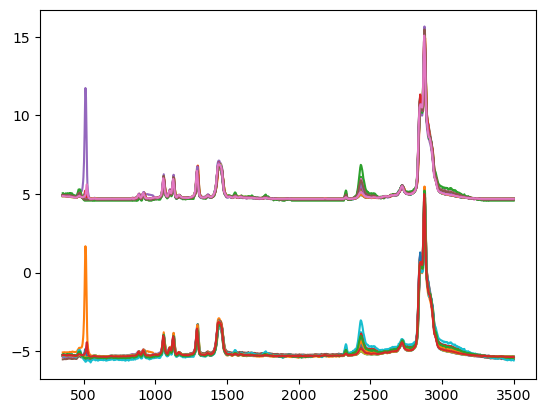

Zinc Stearate


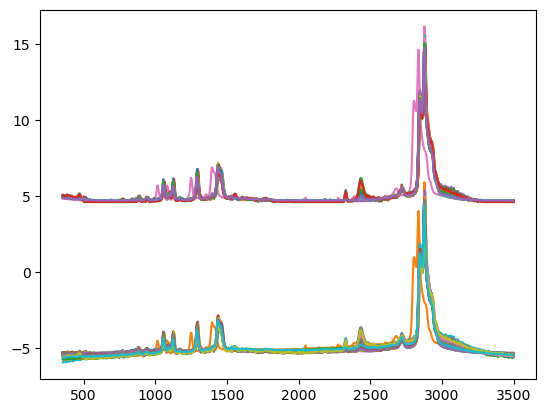

In [54]:
for i in range(4):
    poly = np.unique(stearates_df['polymer'])[i]
    print(poly)
    _ = plt.plot(stearates_df.query('polymer == @poly').iloc[:,:-4].T+5)
    _ = plt.plot(stearates_no_bc_df.query('polymer == @poly').iloc[:,:-4].T-5)
    _ = plt.show()

Calcium Stearate


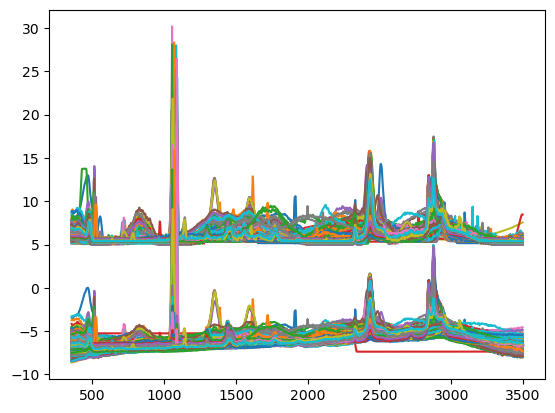

Magnesium Stearate v2


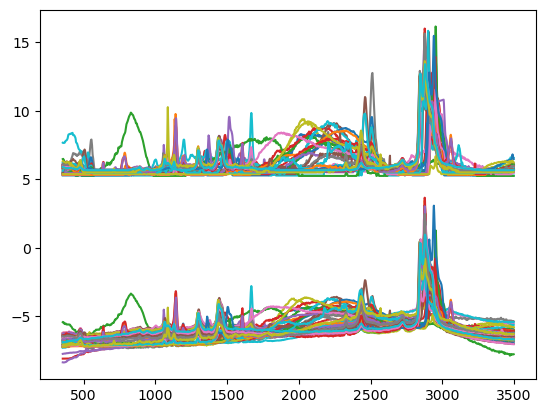

Sodium Stearate


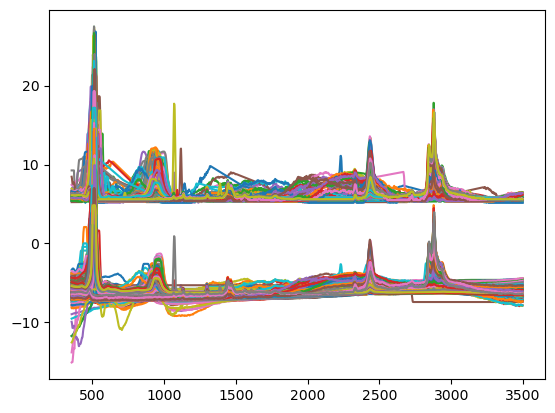

Zinc Stearate


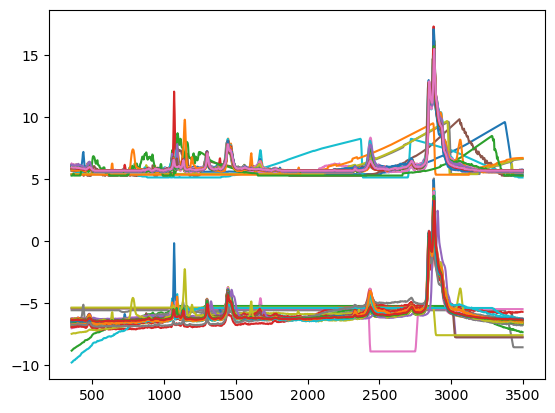

In [57]:
for i in range(4):
    poly = np.unique(stearates_df['polymer'])[i]
    poly_idx = np.array(pred_stearates_df[0]['polymer_ref'] == poly)
    print(poly)
    _ = plt.plot(gloves_data_raman.iloc[:,:-4].loc[poly_idx,:].T+6)
    _ = plt.plot(gloves_data_raman_no_bc.iloc[:,:-4].loc[poly_idx,:].T-6)
    _ = plt.show()

In [88]:
pd.concat([pred_stearates_no_bc_df[0].query('hqi_ref>.7').groupby('polymer_ref').count().iloc[:,:1],
           pred_stearates_no_bc_df[0].query('hqi_ref>.7').groupby('polymer_ref').mean()],axis=1)#.to_csv('gloves_contamination/stearate_matching_no_bc.csv')


,hqi_ref,hqi_ref
polymer_ref,,
Calcium Stearate,564,0.887412
Magnesium Stearate v2,59,0.968127
Sodium Stearate,22,0.984570
Zinc Stearate,61,0.983600


In [89]:
rest_table_no_bc = pd.concat([pred_stearates_no_bc_df[0].groupby('polymer_ref').count().iloc[:,:1],
                              pred_stearates_no_bc_df[0].groupby('polymer_ref').mean(),
                              pred_stearates_no_bc_df[0].query('hqi_ref>.7').groupby('polymer_ref').count().iloc[:,:1],
                              pred_stearates_no_bc_df[0].query('hqi_ref>.7').groupby('polymer_ref').mean()],axis=1)#.to_csv('gloves_contamination/stearate_matching_specy.csv')

rest_table_no_bc.columns = ['# spectra', 'avg hqi', '# spectra (hqi>.7)', 'avg hqi (hqi>.7)']
#rest_table_no_bc.to_csv('gloves_contamination/stearate_matching_np_bs_correct.csv')
rest_table_no_bc


,# spectra,avg hqi,# spectra (hqi>.7),avg hqi (hqi>.7)
polymer_ref,,,,
Calcium Stearate,976,0.757208,564,0.887412
Magnesium Stearate v2,101,0.742954,59,0.968127
Sodium Stearate,100,0.512818,22,0.984570
Zinc Stearate,62,0.976011,61,0.983600


In [92]:
pred_stearates_no_bc_df[0]

,polymer_ref,hqi_ref
0,Sodium Stearate,0.434091
1,Calcium Stearate,0.598475
2,Calcium Stearate,0.474992
3,Sodium Stearate,0.455480
4,Calcium Stearate,0.580216
...,...,...
1234,Sodium Stearate,0.979642
1235,Calcium Stearate,0.949241
1236,Calcium Stearate,0.746652
1237,Calcium Stearate,0.994389


In [111]:
gloves_data_raman_no_bc_res = gloves_data_raman_no_bc.copy()
gloves_data_raman_no_bc_res['polymer_no_baseline_corr'] = pred_stearates_no_bc_df[0]['polymer_ref']
gloves_data_raman_no_bc_res['hqi_no_baseline_corr'] = pred_stearates_no_bc_df[0]['hqi_ref']

gloves_data_raman_no_bc_res['polymer_specy'] = pred_stearates_df[0]['polymer_ref']
gloves_data_raman_no_bc_res['hqi_specy'] = pred_stearates_df[0]['hqi_ref']

(gloves_data_raman_no_bc_res.query('hqi_no_baseline_corr > .7').shape,
 gloves_data_raman_no_bc_res.query('hqi_specy > .7').shape)

((706, 1580), (657, 1580))

In [114]:
gloves_data_raman_no_bc_res.query('hqi_no_baseline_corr > .7 and hqi_specy <= .7').to_csv('gloves_contamination/stearate_spectra_no_match_specy.csv')


In [110]:
pred_stearates_df[0].query('hqi_ref>.7')

,polymer_ref,hqi_ref
75,Calcium Stearate,0.809885
76,Calcium Stearate,0.891150
80,Calcium Stearate,0.922769
81,Calcium Stearate,0.892321
82,Calcium Stearate,0.869911
...,...,...
1234,Sodium Stearate,0.980794
1235,Calcium Stearate,0.959347
1236,Calcium Stearate,0.742729
1237,Zinc Stearate,0.995632


In [108]:
pd.concat([pred_stearates_df[0].query('hqi_ref>.7').groupby('polymer_ref').count().iloc[:,:1],
           pred_stearates_df[0].query('hqi_ref>.7').groupby('polymer_ref').mean()],axis=1)#.to_csv('gloves_contamination/stearate_matching_specy.csv')


,hqi_ref,hqi_ref
polymer_ref,,
Calcium Stearate,492,0.906491
Magnesium Stearate v2,31,0.978601
Sodium Stearate,64,0.938993
Zinc Stearate,70,0.990776


In [109]:
rest_table = pd.concat([pred_stearates_df[0].groupby('polymer_ref').count().iloc[:,:1],
                        pred_stearates_df[0].groupby('polymer_ref').mean(),
                        pred_stearates_df[0].query('hqi_ref>.7').groupby('polymer_ref').count().iloc[:,:1],
                        pred_stearates_df[0].query('hqi_ref>.7').groupby('polymer_ref').mean()],axis=1)#.to_csv('gloves_contamination/stearate_matching_specy.csv')

rest_table.columns = ['# spectra', 'avg hqi', '# spectra (hqi>.7)', 'avg hqi (hqi>.7)']
rest_table.to_csv('gloves_contamination/stearate_matching_specy.csv')
rest_table

,# spectra,avg hqi,# spectra (hqi>.7),avg hqi (hqi>.7)
polymer_ref,,,,
Calcium Stearate,955,0.703030,492,0.906491
Magnesium Stearate v2,51,0.679194,31,0.978601
Sodium Stearate,163,0.583315,64,0.938993
Zinc Stearate,70,0.990776,70,0.990776


In [107]:
rest_table.sum()

# spectra             1239.000000
avg hqi                  2.956316
# spectra (hqi>.7)     657.000000
avg hqi (hqi>.7)         3.814861
dtype: float64

In [67]:
rest_table_no_bc.sum()

# spectra             1239.000000
avg hqi                  2.988991
# spectra (hqi>.7)     706.000000
avg hqi (hqi>.7)         3.823709
dtype: float64

In [39]:
import seaborn as sns

In [75]:
idx_match = np.logical_and(pred_stearates_df[0]['hqi_ref'] > .7,
               pred_stearates_no_bc_df[0]['hqi_ref'] > .7)

In [97]:
from sklearn.metrics import confusion_matrix

mat = confusion_matrix(np.array(pred_stearates_df[0]['polymer_ref'].loc[idx_match]), 
                       np.array(pred_stearates_no_bc_df[0]['polymer_ref'].loc[idx_match]),
                       labels=np.unique(np.array(pred_stearates_df[0]['polymer_ref'])))

mat = (mat / mat.sum(1)[:,None])
mat

array([[0.93195876, 0.04329897, 0.00618557, 0.0185567 ],
       [0.05882353, 0.82352941, 0.        , 0.11764706],
       [0.63934426, 0.04918033, 0.31147541, 0.        ],
       [0.17142857, 0.14285714, 0.        , 0.68571429]])

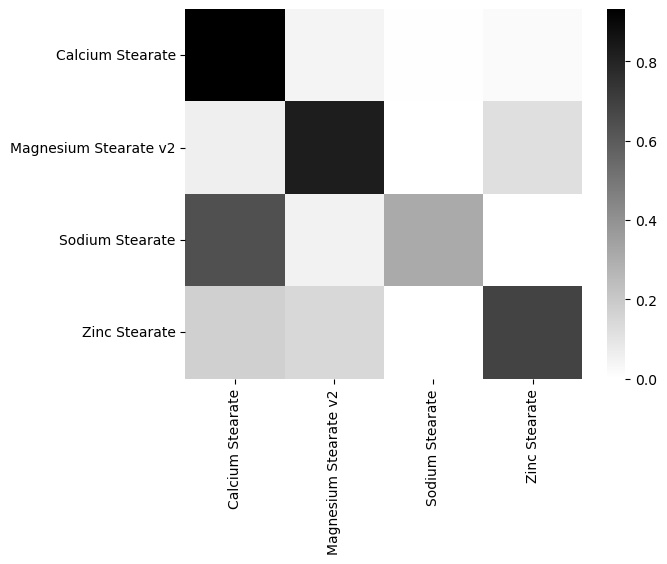

In [96]:
_ = sns.heatmap(mat, 
                #annot=True,
                yticklabels=np.unique(np.array(pred_stearates_df[0]['polymer_ref'])), 
                xticklabels=np.unique(np.array(pred_stearates_df[0]['polymer_ref'])),
                cmap = 'binary')